<a href="https://colab.research.google.com/github/ofshadowmonarch-netizen/mpp/blob/main/Mp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Complex number
import cmath
import matplotlib.pyplot as plt

original = 2 + 1j

translated = original + (2 + 3j)

scaled = original * 2

angle = cmath.pi / 4
rotated = original * cmath.exp(1j * angle)

reflected = original.conjugate()

print("Translation: ",translated)
print("Scaling: ",scaled)
print("Rotation: ", rotated)
print("Reflection: ", reflected)

Translation:  (4+4j)
Scaling:  (4+2j)
Rotation:  (0.7071067811865477+2.1213203435596424j)
Reflection:  (2-1j)


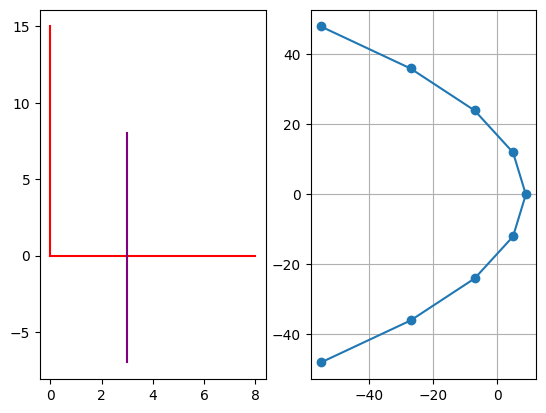

In [10]:
#complex function plotting
import matplotlib.pyplot as plt
import numpy as np

x = [0, 1, 2, 3, 4, 5, 6, 7, 8]
y1 = [0, 0, 0, 0, 0, 0, 0, 0, 0]

x1 = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
y2 = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

x3 = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
y3 = [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]

y = np.arange(-4, 5)
z = 3 + 2j * y

z2 = z**2

plt.subplot(1, 2, 2)
plt.plot(z2.real, z2.imag, 'o-')

plt.grid(True)

plt.subplot(1, 2, 1)
plt.plot(x, y1, color="red")
plt.plot(x1, y2, color="red")
plt.plot(x3, y3, color="purple")

plt.show()

In [11]:
#gauss lagure for 4 points
import numpy as np
def func(x):
    return np.exp(x) * (1/(1+x**2))

w=np.array([0.603154,0.357419,0.038888,0.000539 ])
q=np.array([0.322548,1.74576,4.53662,9.39507])
output=np.sum(w*func(q))
print(output)

1.501150446419145


In [12]:
#gausse lagure for two points
import numpy as np
def func(x):
    return np.exp(x) * (1/(1+x**2))

w1=0.853
w2=0.146

q1=0.58
q2=3.4142

output=w1*func(q1) + w2*func(q2)
print(output)

1.490585247606693


In [13]:
# descrete fourier transform :
import math

def simple_dft(signal):
    N = len(signal)
    F = []

    for k in range(N):
        total = 0

        for n in range(N):
            theta = (2 * math.pi * k * n) / N
            e_power = math.e ** (-1j * theta)
            total += signal[n] * e_power

        F.append(total)

    return F

input_data = [1, 2, 3, 4]
answer = simple_dft(input_data)

print(answer)

[(10+0j), (-2.0000000000000004+1.9999999999999996j), (-2-9.797174393178826e-16j), (-1.9999999999999982-2.000000000000001j)]


In [14]:
# Shooting Method
import numpy as np

def f(x, y1, y2):
  return -y1

def rk4_step(x, y1, y2, h):
  k1_y1 = y2
  k1_y2 = f(x, y1, y2)

  k2_y1 = y2 + 0.5 * h * k1_y2
  k2_y2 = f(x + 0.5 * h, y1 + 0.5 * h * k1_y1, y2 + 0.5 * h * k1_y2)

  k3_y1 = y2 + 0.5 * h * k2_y2
  k3_y2 = f(x + 0.5 * h, y1 + 0.5 * h * k2_y1, y2 + 0.5 * h * k2_y2)

  k4_y1 = y2 + h * k3_y2
  k4_y2 = f(x + h, y1 + h * k3_y1, y2 + h * k3_y2)

  y1_next = y1 + (h / 6.0) * (k1_y1 + 2 * k2_y1 + 2 * k3_y1 + k4_y1)
  y2_next = y2 + (h / 6.0) * (k1_y2 + 2 * k2_y2 + 2 * k3_y2 + k4_y2)

  return y1_next, y2_next

def solve_ivp(z, x_start, x_end, n_steps):
  h = (x_end - x_start) / n_steps
  x = x_start
  y1 = 0.0
  y2 = z

  for _ in range(n_steps):
    y1, y2 = rk4_step(x, y1, y2, h)
    x += h

  return y1


def shooting_method(x_start, x_end, y_target, n_steps, tol=1e-6, max_iter=50):

  z1 = 1.0
  z2 = 2.0

  for _ in range(max_iter):
    val1 = solve_ivp(z1, x_start, x_end, n_steps) - y_target
    val2 = solve_ivp(z2, x_start, x_end, n_steps) - y_target

    if abs(val2) < tol:
      return z2

    z_next = z2 - val2 * (z2 - z1) / (val2 - val1)

    z1 = z2
    z2 = z_next

  raise ValueError("Shooting method is not converge.")

x_start = 0.0
x_end = np.pi / 2
y_target = 1.0
n_steps = 100

optimal_z = shooting_method(x_start, x_end, y_target, n_steps)
print(f"Optimal initial slope (z): {optimal_z:.5f}")

Optimal initial slope (z): 1.00000


In [15]:
#Computation of Fast Fourier Transform

import numpy as np

N = 64
L = 10.0
x = np.linspace(-L/2, L/2, N, endpoint=False)

f_x = np.exp(-x**2)

fft_result = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f_x)))

print(f"{'x':>8} | {'f(x) = exp(-x^2)':>18} | {'|FFT|':>12}")
print("-" * 44)
for i in range(N // 2 - 4, N // 2 + 5):
    print(f"{x[i]:8.3f} | {f_x[i]:18.6f} | {np.abs(fft_result[i]):12.6f}")

       x |   f(x) = exp(-x^2) |        |FFT|
--------------------------------------------
  -0.625 |           0.676634 |     2.338539
  -0.469 |           0.802738 |     4.666450
  -0.312 |           0.906961 |     7.643677
  -0.156 |           0.975882 |    10.277601
   0.000 |           1.000000 |    11.343705
   0.156 |           0.975882 |    10.277601
   0.312 |           0.906961 |     7.643677
   0.469 |           0.802738 |     4.666450
   0.625 |           0.676634 |     2.338539


In [16]:
# Computation of Discrete Fourier Transform


import cmath

def compute_dft(x):
    N = len(x)
    X = []
    for k in range(N):
        total = complex(0, 0)
        for n in range(N):
            angle = -2j * cmath.pi * k * n / N
            total += x[n] * cmath.exp(angle)
        X.append(total)
    return X

signal = [1.0, 2.0, 3.0, 4.0]
dft_result = compute_dft(signal)

print("Input Signal:", signal)
print("DFT Output:")
for k, val in enumerate(dft_result):
    print(f"X[{k}] = {val:.4f}")

Input Signal: [1.0, 2.0, 3.0, 4.0]
DFT Output:
X[0] = 10.0000+0.0000j
X[1] = -2.0000+2.0000j
X[2] = -2.0000-0.0000j
X[3] = -2.0000-2.0000j


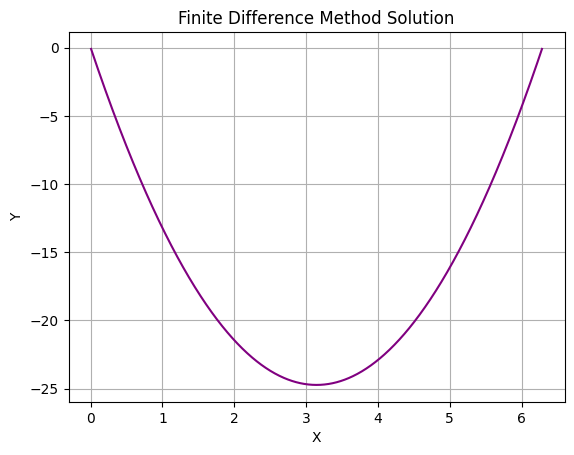

In [17]:
# Finite Difference Method
import matplotlib.pyplot as plt
import numpy as np

n = 1000
x_start, x_end = 0, 2 * np.pi
h = (x_end - x_start) / n

p = 0
q = 0

X = np.linspace(x_start + h, x_end, n)
A = np.zeros((n, n))
R = np.zeros(n)

for i in range(n):
    A[i, i] = -2 + q * (h**2)
    R[i] = 5 * (h**2)

    if i > 0:
        A[i, i - 1] = 1 - (h * p / 2)
    if i < n - 1:
        A[i, i + 1] = 1 + (h * p / 2)

Y = np.linalg.solve(A, R)

plt.plot(X, Y, label="Solution", color="purple")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Finite Difference Method Solution")
plt.grid(True)
plt.show()

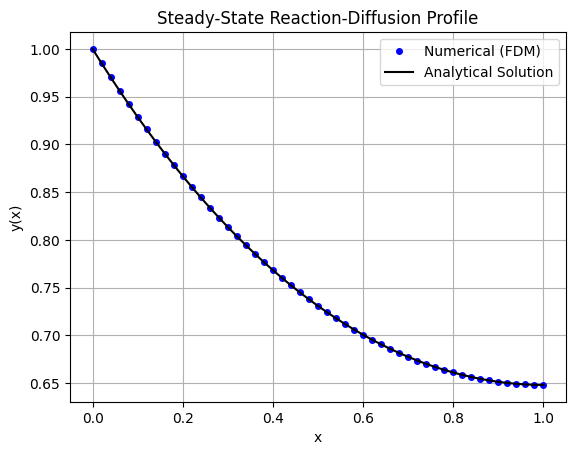

In [18]:

import numpy as np
import matplotlib.pyplot as plt

N = 50
h = 1.0 / N
x = np.linspace(0, 1, N + 1)

A = np.zeros((N, N))
b = np.zeros(N)

for i in range(N - 1):
    A[i, i] = -(2.0 + h**2)
    A[i, i + 1] = 1.0
    if i > 0:
        A[i, i - 1] = 1.0

b[0] = -1.0

A[N - 1, N - 2] = 2.0
A[N - 1, N - 1] = -(2.0 + h**2)

y = np.zeros(N + 1)
y[0] = 1.0
y[1:] = np.linalg.solve(A, b)

y_exact = np.cosh(1 - x) / np.cosh(1)

plt.plot(x, y, 'bo', markersize=4, label="Numerical (FDM)")
plt.plot(x, y_exact, 'k-', label="Analytical Solution")
plt.title("Steady-State Reaction-Diffusion Profile")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.legend()
plt.grid(True)
plt.show()